# 03 · Supuestos y suavizado

**Fase del plan:** F3 – Supuestos.

**Objetivo:** convertir las series anuales de cada país en curvas suaves $X_i^{(k)}(t)$ y verificar los supuestos que necesitan el FPCA y el MFPCA:
1. **Suavidad:** suavizado con B-splines penalizados y $\lambda$ elegido por GCV.
2. **Pertenencia a $L^2$:** normas finitas.
3. **Condición S4 de Chiou et al. (2014):** $\min_t \hat v_k(t) > 0$, necesaria para la normalización $Z=(X-\hat\mu)/\sqrt{\hat v}$.

Se trabaja primero en el horizonte principal 1950–2023 y, una vez revisado, se repite para 1950–2100 (sensibilidad).

**Entradas:** `output/data/matrices_1950_2023.rds`, `output/data/matrices_1950_2100.rds`, `output/data/meta_paises.rds`, `output/data/config.rds`. Se excluyen los países pequeños ($n = 200$).

**Salidas:**
- `output/data/curvas_suaves_1950_2023.rds` y `curvas_suaves_1950_2100.rds`: listas de matrices país × año (mismo formato que en F1, con 200 filas).
- `output/data/fd_1950_2023.rds` y `fd_1950_2100.rds`: objetos `fd` por indicador, con su $\lambda$.
- Tablas `output/tables/sup_lambda_*.csv`, `sup_L2_1950_2023.csv`, `sup_S4_*.csv` y figuras `sup_*`.


## Configuración


In [1]:
suppressPackageStartupMessages({
  library(fda)         # antes que tidyverse: fda carga MASS, que enmascara dplyr::select
  library(tidyverse)
  library(patchwork)
  library(here)
})
cfg <- readRDS(here::here("output/data/config.rds")); invisible(list2env(cfg, envir = globalenv())); set.seed(SEED)
options(repr.plot.width = 12, repr.plot.height = 7, repr.plot.res = 120, width = 150)

meta_paises <- readRDS(here::here("output/data/meta_paises.rds"))
meta <- meta_paises |> filter(!es_pequeno)
IND <- replace(IND_AMPLIADO, IND_AMPLIADO == "CNMR", "CNMR_t")
CAPTION <- "Fuente: UN WPP 2024"
GRID_LAMBDA <- 10^seq(-4, 4, by = 0.5)

mats_23 <- lapply(readRDS(here::here("output/data/matrices_1950_2023.rds")), \(M) M[meta$ISO3_code, ])
stopifnot(nrow(meta) == 200, identical(names(mats_23), IND),
          all(sapply(mats_23, \(M) identical(dim(M), c(200L, 74L)) && !anyNA(M))))
stopifnot(identical(select, dplyr::select))
cat("Indicadores:", IND, "| países:", nrow(meta), "| rejilla λ:", length(GRID_LAMBDA), "valores\n")


Indicadores: TFR LEx CNMR_t MAC MedianAgePop | países: 200 | rejilla λ: 17 valores


## Funciones de suavizado

Para cada indicador $k$ y país $i$ se ajusta
$$
\hat X_i^{(k)}=\arg\min_{x}\sum_{j}\big(y_{ij}-x(t_j)\big)^2+\lambda_k\int \big(D^2x(t)\big)^2\,dt,
$$
con $x(t)=\sum_m c_m B_m(t)$ en una base B-spline cúbica (orden 4) con nodos en cada año. Con $74$ años hay $74+2=76$ funciones base. La penalización sobre la segunda derivada controla la curvatura: con $\lambda\to 0$ la curva interpola los datos y con $\lambda\to\infty$ tiende a una recta.

El criterio de validación cruzada generalizada de cada curva es
$$
\mathrm{GCV}_i(\lambda)=\frac{n_t\,\mathrm{SSE}_i(\lambda)}{\big(n_t-\mathrm{df}(\lambda)\big)^2},
$$
donde $\mathrm{df}(\lambda)=\operatorname{tr}\mathbf S_\lambda$ son los grados de libertad efectivos. Se usa un **$\lambda$ común por indicador**, el que minimiza $\sum_i \mathrm{GCV}_i(\lambda)$ en la rejilla $10^{-4},10^{-3.5},\dots,10^{4}$. Así todas las curvas de un mismo indicador tienen el mismo grado de suavidad, algo necesario para que las comparaciones entre países en el FPCA sean coherentes.


In [2]:
base_bspline <- function(anios) create.bspline.basis(range(anios), norder = 4, breaks = anios)

# GCV total (suma sobre países) para cada λ de la rejilla
perfil_gcv <- function(M, anios, grid = GRID_LAMBDA) {
  b <- base_bspline(anios)
  map_dfr(grid, function(l) {
    s <- smooth.basis(anios, t(M), fdPar(b, Lfdobj = 2, lambda = l))
    tibble(lambda = l, gcv_total = sum(s$gcv), df = s$df)
  })
}

# Suavizado con el λ elegido: devuelve el fd, la matriz evaluada en la rejilla anual y diagnósticos
suavizar <- function(M, anios, lambda) {
  b <- base_bspline(anios)
  s <- smooth.basis(anios, t(M), fdPar(b, Lfdobj = 2, lambda = lambda))
  S <- t(eval.fd(anios, s$fd))
  dimnames(S) <- dimnames(M)
  list(fd = s$fd, lambda = lambda, df = s$df, suave = S,
       rmse = sqrt(mean((M - S)^2)), rmse_rel = sqrt(mean((M - S)^2)) / sd(M))
}

# Paso completo para un horizonte: perfiles GCV, λ óptimo y suavizado de cada indicador
procesar_horizonte <- function(mats, anios) {
  perfiles <- imap_dfr(mats, \(M, ind) perfil_gcv(M, anios) |> mutate(indicador = ind))
  lambdas  <- perfiles |> group_by(indicador) |> slice_min(gcv_total, n = 1, with_ties = FALSE) |> ungroup()
  ajustes  <- imap(mats, \(M, ind) suavizar(M, anios, lambdas$lambda[lambdas$indicador == ind]))
  list(perfiles = perfiles, ajustes = ajustes)
}

tabla_lambdas <- function(res, mats) {
  imap_dfr(res$ajustes, \(a, ind) tibble(
    indicador = ind, lambda = a$lambda, log10_lambda = log10(a$lambda), df = round(a$df, 1),
    rmse = a$rmse, rmse_rel_sd = a$rmse_rel,
    en_borde = a$lambda %in% range(GRID_LAMBDA)))
}

fig_gcv <- function(res, horizonte) {
  opt <- res$perfiles |> group_by(indicador) |> slice_min(gcv_total, n = 1, with_ties = FALSE)
  ggplot(res$perfiles, aes(log10(lambda), gcv_total)) +
    geom_line(colour = "#0072B2", linewidth = 0.9) + geom_point(colour = "#0072B2", size = 1.4) +
    geom_point(data = opt, colour = "#D55E00", size = 3) +
    facet_wrap(~ factor(indicador, levels = IND), scales = "free_y", ncol = 3) +
    scale_y_log10() +
    labs(title = paste0("Criterio GCV total por indicador, ", horizonte[1], "–", horizonte[2]),
         subtitle = "Suma de GCV sobre los 200 países · punto naranja: lambda óptimo",
         x = expression(log[10](lambda)), y = "GCV total (escala log)", caption = CAPTION) +
    theme_minimal(base_size = 11)
}

# S4 de Chiou: varianza puntual mínima entre países de las curvas suavizadas
tabla_S4 <- function(res, anios) {
  imap_dfr(res$ajustes, function(a, ind) {
    v <- apply(a$suave, 2, var)
    tibble(indicador = ind, min_v = min(v), anio_min_v = anios[which.min(v)], max_v = max(v),
           cumple_S4 = min(v) >= 1e-6)
  })
}


# Horizonte principal 1950–2023

## 1. Suavizado: elección de λ por GCV
Se calcula el GCV total en la rejilla de 17 valores de $\lambda$ para cada indicador y se elige el mínimo. Si el óptimo cae en un extremo de la rejilla, se marca con `en_borde = TRUE`.


 log10_lambda     TFR   LEx CNMR_t     MAC MedianAgePop
         -4.0  0.4617 278.3  210.1  0.2805       0.4570
         -3.5  0.4613 278.0  209.6  0.2802       0.4578
         -3.0  0.4601 277.1  208.1  0.2794       0.4603
         -2.5  0.4566 274.6  203.9  0.2772       0.4681
         -2.0  0.4484 268.4  193.9  0.2723       0.4925
         -1.5  0.4343 257.3  177.6  0.2667       0.5646
         -1.0  0.4227 244.0  162.0  0.2706       0.7522
         -0.5  0.4385 234.9  153.4  0.2994       1.1410
          0.0  0.5071 234.4  152.3  0.3668       1.7320
          0.5  0.6476 241.7  158.1  0.4880       2.5300
          1.0  0.8833 253.9  169.8  0.6917       3.7800
          1.5  1.2420 270.4  187.2  1.0290       5.8380
          2.0  1.8120 296.9  210.5  1.6010       9.3090
          2.5  2.8530 342.3  239.4  2.5890      15.2800
          3.0  4.8050 409.8  271.5  4.3440      24.9200
          3.5  8.2870 502.3  304.7  7.5080      41.5800
          4.0 14.1700 632.3  338.0 13.4600      

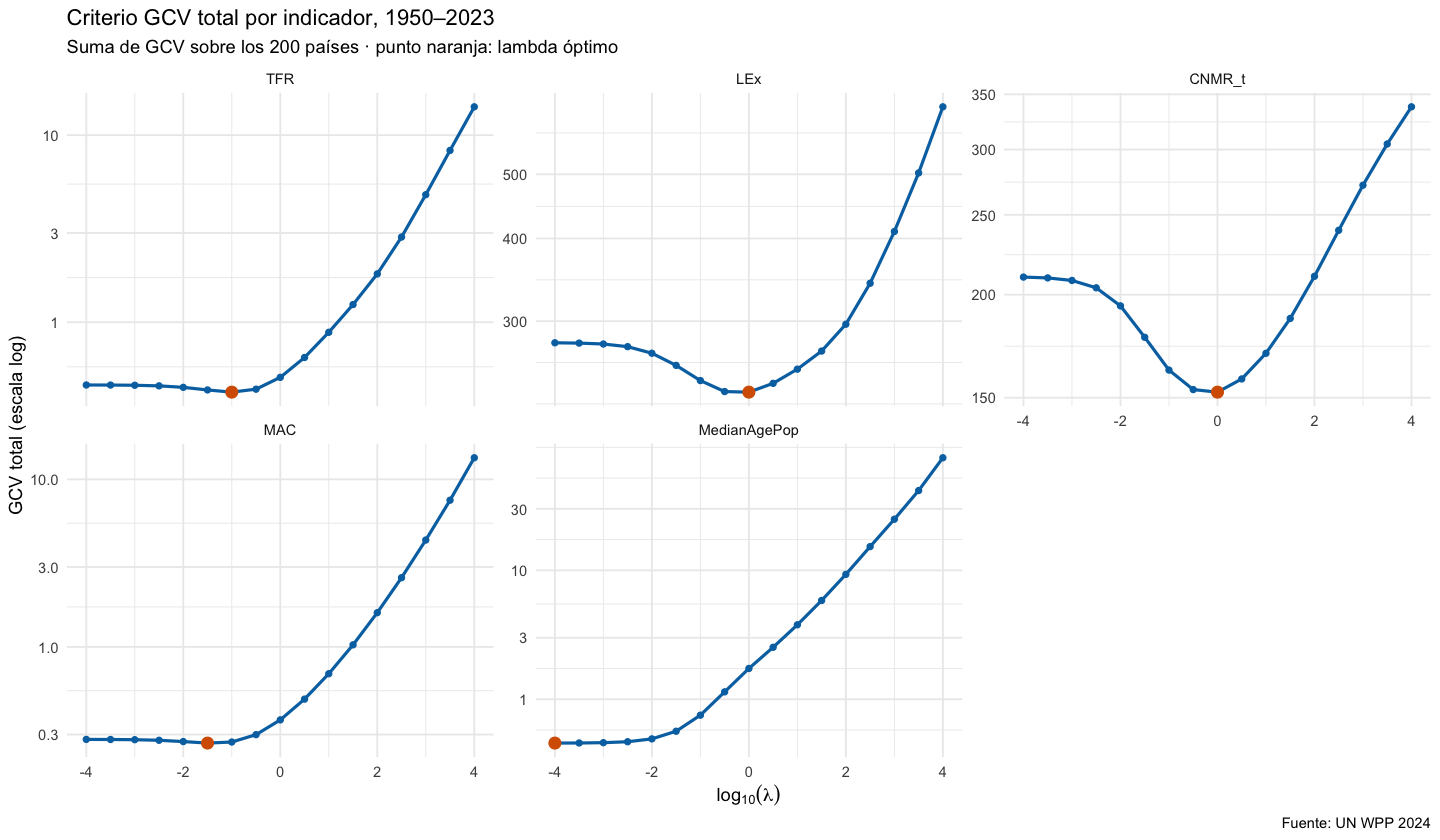

In [3]:
ANIOS_23 <- HORIZONTE[1]:HORIZONTE[2]
res_23 <- procesar_horizonte(mats_23, ANIOS_23)

res_23$perfiles |>
  select(indicador, lambda, gcv_total) |>
  mutate(log10_lambda = log10(lambda), gcv_total = signif(gcv_total, 4)) |>
  select(-lambda) |>
  pivot_wider(names_from = indicador, values_from = gcv_total) |>
  as.data.frame() |> print(row.names = FALSE)

p <- fig_gcv(res_23, HORIZONTE)
guardar_fig(p, "sup_gcv_1950_2023", w = 12, h = 7); p


### λ óptimo y cambio introducido por el suavizado
`rmse` es la raíz del error cuadrático medio entre las series crudas y las suavizadas (en las unidades del indicador), y `rmse_rel_sd` es ese RMSE dividido por la desviación estándar global del indicador. `df` son los grados de libertad efectivos de cada curva (de 76 posibles).


In [4]:
lambdas_23 <- tabla_lambdas(res_23, mats_23)
guardar_tabla(lambdas_23, "sup_lambda_1950_2023", tex = TRUE)
lambdas_23 |> mutate(across(c(rmse, rmse_rel_sd), ~ signif(.x, 3))) |> as.data.frame() |> print(row.names = FALSE)


    indicador     lambda log10_lambda   df     rmse rmse_rel_sd en_borde
          TFR 0.10000000         -1.0 45.9 1.74e-02    8.54e-03    FALSE
          LEx 1.00000000          0.0 27.0 6.87e-01    5.57e-02    FALSE
       CNMR_t 1.00000000          0.0 27.0 5.54e-01    2.59e-01    FALSE
          MAC 0.03162278         -1.5 57.2 8.29e-03    5.77e-03    FALSE
 MedianAgePop 0.00010000         -4.0 73.9 6.61e-05    8.64e-06     TRUE


### Crudo frente a suavizado en seis países
Se eligen los 3 países con mayor varianza temporal de CNMR_t (los más volátiles en migración) y los 3 con menor, y se muestran los cinco indicadores. Los puntos son los datos anuales y la línea es la curva suavizada.


# A tibble: 6 × 4
  ISO3_code pais                     var_CNMR_t grupo         
  <chr>     <chr>                         <dbl> <chr>         
1 MAC       China, Macao SAR (MAC)       11.0   mayor varianza
2 OMN       Oman (OMN)                    9.07  mayor varianza
3 ARM       Armenia (ARM)                 8.50  mayor varianza
4 HTI       Haiti (HTI)                   0.021 menor varianza
5 DOM       Dominican Republic (DOM)      0.031 menor varianza
6 MDG       Madagascar (MDG)              0.053 menor varianza


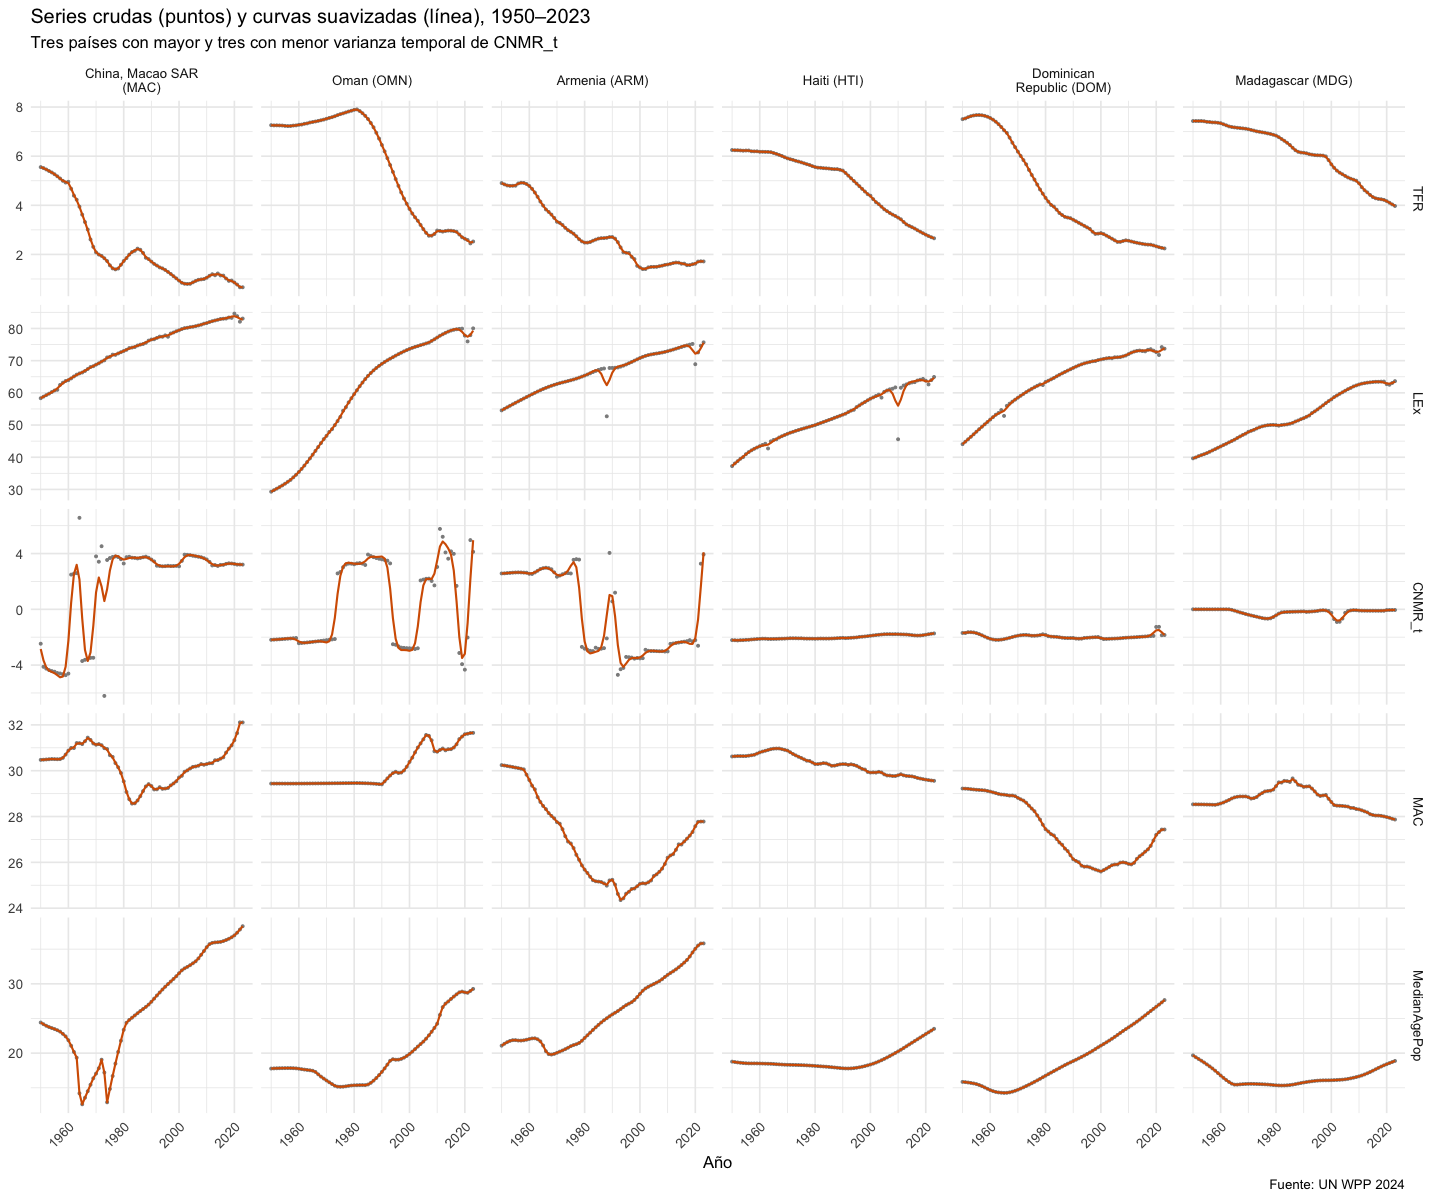

In [5]:
var_cnmr <- apply(mats_23$CNMR_t, 1, var)
sel <- c(names(sort(var_cnmr, decreasing = TRUE))[1:3], names(sort(var_cnmr))[1:3])
etiq_sel <- setNames(paste0(meta$Location[match(sel, meta$ISO3_code)], " (", sel, ")"), sel)
print(tibble(ISO3_code = sel, pais = etiq_sel, var_CNMR_t = round(var_cnmr[sel], 3),
             grupo = rep(c("mayor varianza", "menor varianza"), each = 3)))

fig_crudo_suave <- function(mats, res, anios, sel, horizonte) {
  d <- imap_dfr(mats, function(M, ind) {
    tibble(indicador = ind, ISO3_code = rep(sel, times = length(anios)),
           Time = rep(anios, each = length(sel)),
           crudo = as.vector(M[sel, , drop = FALSE]),
           suave = as.vector(res$ajustes[[ind]]$suave[sel, , drop = FALSE]))
  }) |>
    mutate(indicador = factor(indicador, levels = IND),
           pais = factor(etiq_sel[ISO3_code], levels = etiq_sel[sel]))
  ggplot(d, aes(Time)) +
    geom_point(aes(y = crudo), colour = "grey55", size = 0.5) +
    geom_line(aes(y = suave), colour = "#D55E00", linewidth = 0.6) +
    facet_grid(indicador ~ pais, scales = "free_y", labeller = label_wrap_gen(18)) +
    labs(title = paste0("Series crudas (puntos) y curvas suavizadas (línea), ", horizonte[1], "–", horizonte[2]),
         subtitle = "Tres países con mayor y tres con menor varianza temporal de CNMR_t",
         x = "Año", y = NULL, caption = CAPTION) +
    theme_minimal(base_size = 10) +
    theme(axis.text.x = element_text(angle = 45, hjust = 1))
}
p <- fig_crudo_suave(mats_23, res_23, ANIOS_23, sel, HORIZONTE)
options(repr.plot.height = 10)
guardar_fig(p, "sup_crudo_vs_suave_1950_2023", w = 14, h = 11); p
options(repr.plot.height = 7)


**Lectura del suavizado (1950–2023).**
- **TFR, MAC y MedianAgePop casi no cambian**, como se esperaba. El RMSE relativo es < 1 % de la desviación estándar del indicador (0.85 %, 0.58 % y ≈ 0 %). Para MedianAgePop el GCV elige el extremo inferior de la rejilla ($\lambda=10^{-4}$, df ≈ 74), es decir, prácticamente interpolación: la serie ya es suave porque la ONU la deriva de la estructura por edad. Ampliar la rejilla hacia abajo no cambiaría nada en la práctica (RMSE = 7·10⁻⁵ años).
- **CNMR_t es el indicador más modificado**, como se esperaba: $\lambda=1$, df ≈ 27 y RMSE relativo del 26 %. El suavizado recorta los picos de un año (Macao 1964, Omán 2019–2021, Armenia 1988–1992) y conserva los cambios de régimen migratorio que duran varios años.
- **LEx** también usa $\lambda=1$ (df ≈ 27), pero con un RMSE relativo de solo 5.6 %. El cambio se concentra en las crisis de un solo año (terremoto de Armenia de 1988, terremoto de Haití de 2010, COVID-19 2020–2021), que pasan de picos agudos a valles más anchos y menos profundos. Para el análisis de trayectorias es aceptable, pero estas crisis quedan atenuadas en las curvas suaves.


## 2. Pertenencia a $L^2$
Para cada curva suavizada se calcula su norma
$$
\|X_i^{(k)}\|_{L^2}=\Big(\int_{1950}^{2023}X_i^{(k)}(t)^2\,dt\Big)^{1/2},
$$
aproximando la integral con la regla del trapecio sobre la rejilla anual: $\int f\approx\sum_{j}\tfrac{1}{2}\big(f(t_j)+f(t_{j+1})\big)(t_{j+1}-t_j)$. El supuesto exige que todas las normas sean finitas. Con curvas continuas en un intervalo compacto esto se cumple siempre; el check confirma que no hay valores `NA`, `Inf` ni explosiones numéricas.


In [6]:
norma_L2 <- function(S, anios) {
  h <- diff(anios)
  sqrt(apply(S^2, 1, function(f) sum(h * (head(f, -1) + tail(f, -1)) / 2)))
}

normas_23 <- imap(res_23$ajustes, \(a, ind) norma_L2(a$suave, ANIOS_23))
tabla_L2 <- imap_dfr(normas_23, \(x, ind) tibble(
  indicador = ind, min = min(x), Q1 = quantile(x, 0.25, names = FALSE), mediana = median(x),
  media = mean(x), Q3 = quantile(x, 0.75, names = FALSE), max = max(x), todas_finitas = all(is.finite(x))))

stopifnot(all(tabla_L2$todas_finitas), all(sapply(normas_23, length) == 200))
guardar_tabla(tabla_L2, "sup_L2_1950_2023", tex = TRUE)
tabla_L2 |> mutate(across(where(is.double), ~ round(.x, 2))) |> as.data.frame() |> print(row.names = FALSE)


    indicador    min     Q1 mediana  media     Q3    max todas_finitas
          TFR  14.82  23.81   38.53  36.96  48.52  64.50          TRUE
          LEx 336.26 476.98  555.61 541.35 606.12 662.01          TRUE
       CNMR_t   2.01  11.85   15.67  16.26  20.43  36.67          TRUE
          MAC 216.64 239.27  246.68 245.69 251.90 269.21          TRUE
 MedianAgePop 126.86 152.51  182.49 200.37 244.42 322.38          TRUE


## 3. Condición S4 de Chiou: $\min_t \hat v_k(t) > 0$
La normalización de Chiou et al. (2014) divide por $\sqrt{\hat v_k(t)}$, así que exige que la varianza entre países de las curvas suavizadas sea estrictamente positiva en todo $t$. Si en algún año todos los países tuvieran casi el mismo valor, la normalización amplificaría ruido. Se usa el umbral numérico $10^{-6}$.


In [7]:
S4_23 <- tabla_S4(res_23, ANIOS_23)
guardar_tabla(S4_23, "sup_S4_1950_2023", tex = TRUE)
S4_23 |> mutate(across(c(min_v, max_v), ~ signif(.x, 4))) |> as.data.frame() |> print(row.names = FALSE)
if (any(!S4_23$cumple_S4)) stop("S4 falla: algún min_t v(t) < 1e-6. Detenerse y revisar.")
cat("S4 se cumple para los", nrow(S4_23), "indicadores.\n")


    indicador  min_v anio_min_v   max_v cumple_S4
          TFR  1.531       2023   4.226      TRUE
          LEx 51.430       2023 137.100      TRUE
       CNMR_t  2.631       2021   4.928      TRUE
          MAC  1.107       1950   2.707      TRUE
 MedianAgePop 21.310       1950  89.150      TRUE
S4 se cumple para los 5 indicadores.


## 4. Guardado (1950–2023)
- `curvas_suaves_1950_2023.rds`: lista nombrada por indicador de matrices 200 × 74 (filas = `ISO3_code` en el orden de `meta_paises` sin pequeños, columnas = año), evaluadas en la rejilla anual.
- `fd_1950_2023.rds`: por indicador, el objeto `fd` (76 coeficientes por país), el $\lambda$ elegido y los grados de libertad.


In [8]:
guardar_horizonte <- function(res, sufijo) {
  curvas <- lapply(res$ajustes, `[[`, "suave")
  fds    <- lapply(res$ajustes, \(a) list(fd = a$fd, lambda = a$lambda, df = a$df))
  saveRDS(curvas, here::here("output/data", paste0("curvas_suaves_", sufijo, ".rds")))
  saveRDS(fds,    here::here("output/data", paste0("fd_", sufijo, ".rds")))
  # Verificación: relectura y coherencia entre fd y curvas evaluadas
  c2 <- readRDS(here::here("output/data", paste0("curvas_suaves_", sufijo, ".rds")))
  f2 <- readRDS(here::here("output/data", paste0("fd_", sufijo, ".rds")))
  anios <- as.numeric(colnames(c2[[1]]))
  stopifnot(identical(names(c2), IND), identical(names(f2), IND),
            all(sapply(c2, \(S) identical(rownames(S), meta$ISO3_code) && !anyNA(S))),
            all(sapply(IND, \(ind) max(abs(t(eval.fd(anios, f2[[ind]]$fd)) - c2[[ind]])) < 1e-10)))
  cat("Guardado", sufijo, ":", length(c2), "indicadores, matrices", paste(dim(c2[[1]]), collapse = " × "),
      "| coeficientes fd por país:", nrow(f2[[1]]$fd$coefs), "\n")
}
guardar_horizonte(res_23, "1950_2023")


Guardado 1950_2023 : 5 indicadores, matrices 200 × 74 | coeficientes fd por país: 76 


# Horizonte de sensibilidad 1950–2100

Se repiten el suavizado (punto 1), la condición S4 (punto 3) y el guardado (punto 4) con el horizonte extendido, que incluye la proyección de la variante media (2024–2100). La base tiene ahora nodos en cada año de 1950 a 2100, es decir, $151+2=153$ funciones base. El $\lambda$ se elige de nuevo por GCV, porque la proyección de la ONU es mucho más suave que las estimaciones y eso puede cambiar el óptimo.

## 1b. Suavizado: elección de λ por GCV (1950–2100)


    indicador     lambda log10_lambda    df     rmse rmse_rel_sd en_borde
          TFR 0.10000000         -1.0  93.0 1.22e-02    6.59e-03    FALSE
          LEx 1.00000000          0.0  54.2 4.85e-01    3.70e-02    FALSE
       CNMR_t 0.31622777         -0.5  71.5 3.32e-01    1.98e-01    FALSE
          MAC 0.03162278         -1.5 116.2 5.84e-03    3.36e-03    FALSE
 MedianAgePop 0.00010000         -4.0 150.8 4.67e-05    3.86e-06     TRUE


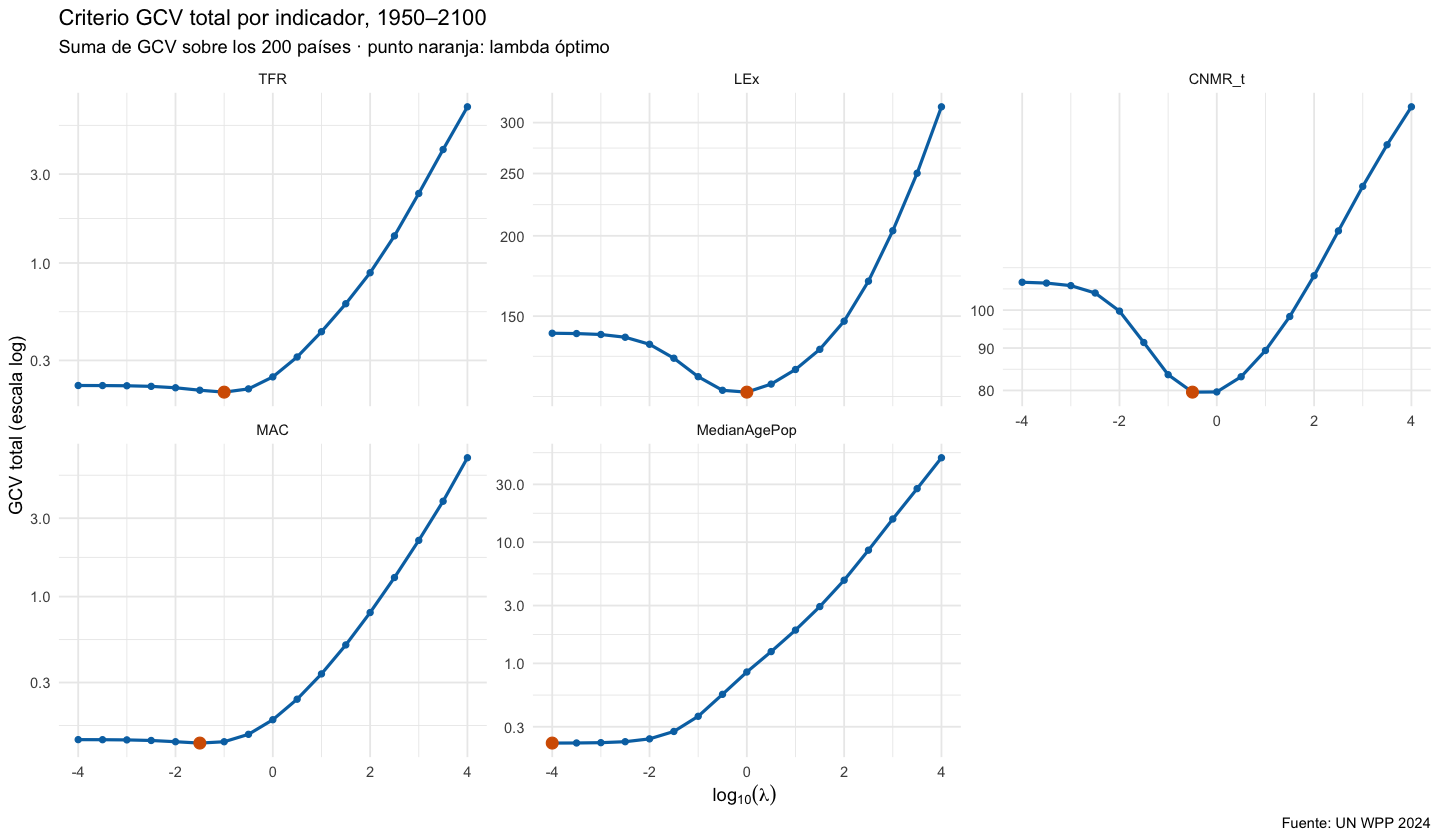

In [9]:
ANIOS_100 <- HORIZONTE_SENS[1]:HORIZONTE_SENS[2]
mats_100 <- lapply(readRDS(here::here("output/data/matrices_1950_2100.rds")), \(M) M[meta$ISO3_code, ])
stopifnot(identical(names(mats_100), IND),
          all(sapply(mats_100, \(M) identical(dim(M), c(200L, 151L)) && !anyNA(M))),
          all(sapply(IND, \(ind) identical(mats_100[[ind]][, as.character(ANIOS_23)], mats_23[[ind]]))))

res_100 <- procesar_horizonte(mats_100, ANIOS_100)
p <- fig_gcv(res_100, HORIZONTE_SENS)
guardar_fig(p, "sup_gcv_1950_2100", w = 12, h = 7); p

lambdas_100 <- tabla_lambdas(res_100, mats_100)
guardar_tabla(lambdas_100, "sup_lambda_1950_2100", tex = TRUE)
lambdas_100 |> mutate(across(c(rmse, rmse_rel_sd), ~ signif(.x, 3))) |> as.data.frame() |> print(row.names = FALSE)


### Crudo frente a suavizado (1950–2100), mismos seis países


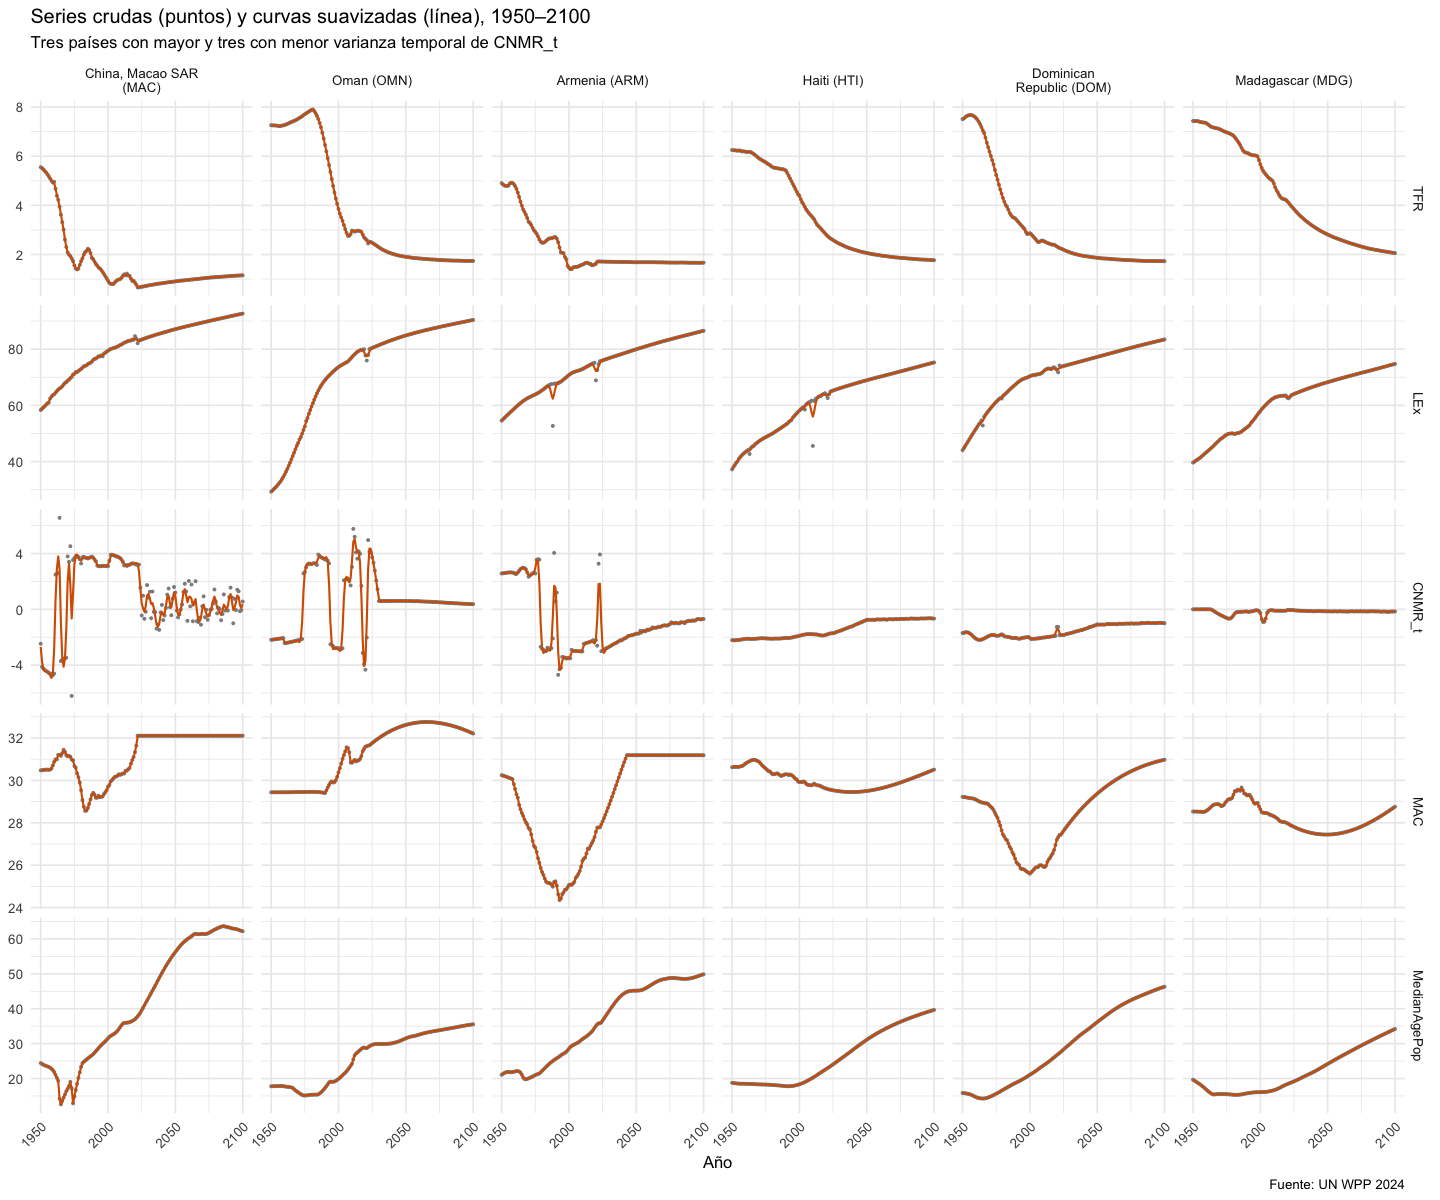

In [10]:
p <- fig_crudo_suave(mats_100, res_100, ANIOS_100, sel, HORIZONTE_SENS)
options(repr.plot.height = 10)
guardar_fig(p, "sup_crudo_vs_suave_1950_2100", w = 14, h = 11); p
options(repr.plot.height = 7)


**Lectura del suavizado (1950–2100).**
- TFR, LEx, MAC y MedianAgePop conservan el mismo $\lambda$ que en 1950–2023. MedianAgePop vuelve a quedar en el borde inferior ($10^{-4}$), por la misma razón que antes: la serie ya es suave.
- **CNMR_t cambia de $\lambda=1$ a $\lambda=10^{-0.5}\approx0.32$.** La proyección 2024–2100 es casi lisa para la mayoría de los países, así que en la suma de GCV pesa más el ajuste fino y el óptimo se desplaza hacia menos suavizado. Como consecuencia, en el tramo 1950–2023 de este horizonte los picos históricos se recortan menos (por ejemplo, Armenia en 2022). **La parte histórica de CNMR_t no es idéntica entre los dos horizontes;** hay que tenerlo en cuenta al comparar soluciones en F8.
- En la proyección aparecen supuestos de la ONU que el análisis por trayectorias va a "ver": MAC constante desde ~2045 en varios países (Macao, Armenia), convergencia de TFR hacia ~1.7–2 y CNMR proyectada con oscilaciones en algunos casos (Macao). Esto refuerza la decisión de usar 1950–2100 solo como sensibilidad.


## 3b. Condición S4 (1950–2100)


In [11]:
S4_100 <- tabla_S4(res_100, ANIOS_100)
guardar_tabla(S4_100, "sup_S4_1950_2100", tex = TRUE)
S4_100 |> mutate(across(c(min_v, max_v), ~ signif(.x, 4))) |> as.data.frame() |> print(row.names = FALSE)
if (any(!S4_100$cumple_S4)) stop("S4 falla: algún min_t v(t) < 1e-6. Detenerse y revisar.")
cat("S4 se cumple para los", nrow(S4_100), "indicadores.\n")


    indicador    min_v anio_min_v   max_v cumple_S4
          TFR  0.04701       2100   4.226      TRUE
          LEx 43.42000       2100 137.100      TRUE
       CNMR_t  0.65390       2099   5.091      TRUE
          MAC  1.10700       1950   3.383      TRUE
 MedianAgePop 21.31000       1950 104.800      TRUE
S4 se cumple para los 5 indicadores.


## 4b. Guardado (1950–2100)
Se guardan `curvas_suaves_1950_2100.rds` (matrices 200 × 151) y `fd_1950_2100.rds` (153 coeficientes por país), con la misma estructura y las mismas verificaciones que en el horizonte principal.


In [12]:
guardar_horizonte(res_100, "1950_2100")


Guardado 1950_2100 : 5 indicadores, matrices 200 × 151 | coeficientes fd por país: 153 


# Limitaciones

**1. La muestra de curvas no es i.i.d.** El FPCA, el MFPCA y las propiedades asintóticas de sus estimadores (consistencia de $\hat\mu$, $\hat v$, autofunciones y scores) suponen que $X_1,\dots,X_n$ son realizaciones independientes e idénticamente distribuidas de un mismo proceso. Los 200 países no cumplen ese supuesto:
- **Dependencia espacial y regional:** países vecinos comparten choques (guerras, crisis económicas, epidemias como el VIH/sida en África austral, la disolución de la URSS) y sus curvas están correlacionadas.
- **Dependencia por flujos:** la migración es un juego de suma cero entre países. La emigración neta de unos es la inmigración neta de otros, así que las curvas de CNMR están ligadas por construcción.
- **Choques comunes:** el COVID-19 en 2020–2021 desplaza a la vez las curvas de LEx y CNMR de casi todos los países.
- **Heterogeneidad:** las regiones no son submuestras de una misma distribución.

**Consecuencia:** el MFPCA y el clustering se usan como herramientas **descriptivas y exploratorias**. No se hace inferencia que dependa del supuesto i.i.d. (intervalos o contrastes sobre autofunciones o scores). La estabilidad de los grupos se evalúa por remuestreo (`clusterboot`, F6), entendiéndola como robustez y no como inferencia poblacional.

**2. fChange no aplica.** Los métodos de detección de cambios estructurales en series de tiempo funcionales (`fChange`) suponen una secuencia de curvas **indexada por el tiempo**, $X_1(\cdot),X_2(\cdot),\dots$, por ejemplo una curva por año, y buscan un punto de quiebre en esa secuencia. Aquí las curvas están **indexadas por país**: $X_i(t)$ es la trayectoria del país $i$ y el tiempo es el argumento de la función, no el índice de la muestra. El orden de los países es arbitrario, así que "un cambio en la secuencia" no tiene sentido. Los cambios temporales dentro de cada trayectoria (por ejemplo, el inicio de la transición) quedan capturados por la forma de las autofunciones del FPCA y el MFPCA, no por un test de cambio estructural.


# Conclusiones de F3

**Suavizado (λ común por indicador, elegido por GCV):**

| Indicador | λ 1950–2023 | df | RMSE rel. | λ 1950–2100 | df |
|---|---|---|---|---|---|
| TFR | $10^{-1}$ | 45.9 | 0.85 % | $10^{-1}$ | 93.0 |
| LEx | $10^{0}$ | 27.0 | 5.6 % | $10^{0}$ | 54.2 |
| CNMR_t | $10^{0}$ | 27.0 | 25.9 % | $10^{-0.5}$ | 71.5 |
| MAC | $10^{-1.5}$ | 57.2 | 0.58 % | $10^{-1.5}$ | 116.2 |
| MedianAgePop | $10^{-4}$ (borde) | 73.9 | ≈ 0 % | $10^{-4}$ (borde) | 150.8 |

- **Se cumple lo esperado:** TFR, MAC y MedianAgePop casi no cambian, y CNMR_t es el indicador más suavizado (RMSE de ~26 % de su desviación estándar). LEx cambia poco en general, pero sus crisis de un solo año quedan atenuadas.
- **MedianAgePop** toma el $\lambda$ del borde inferior de la rejilla: la serie ya es suave y equivale a interpolarla. No requiere acción.

**$L^2$:** las 1,000 normas (200 países × 5 indicadores) son finitas, así que se cumple el supuesto.

**S4 de Chiou:** se cumple en ambos horizontes ($\min_t\hat v_k(t)\ge 1.1$ en 1950–2023). **Advertencia para 1950–2100:** la varianza de TFR cae a 0.047 en 2100 (90 veces menos que su máximo), porque la proyección de la ONU hace converger la fecundidad. La normalización de Chiou amplificaría unas 9.5 veces (en desviación estándar) diferencias de TFR muy pequeñas y dependientes del modelo de proyección hacia 2100. Hay que tenerlo presente al interpretar la sensibilidad de F8.

**Para F4–F5:** se usan `curvas_suaves_1950_2023.rds` y `fd_1950_2023.rds` (200 países). Los países pequeños **no** se suavizaron; para la sensibilidad "incluir los 237" de F8 habrá que suavizarlos con los mismos $\lambda$.
